# AdaBoost

AdaBoost combines shallow learners, giving extra attention to cases misclassified during earlier rounds.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Estimator

The constructor below fixes the model used in every fold.

In [2]:
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier
from gallery.tabular import diagnostic_split, classification_report

model = AdaBoostClassifier(n_estimators=80, learning_rate=0.5, random_state=17)

## Data and split

The stratified split reserves a quarter of the records. Malignant is the positive class. Cross-validation and any scaling or calibration use training records only.

In [3]:
X, X_test, y, y_test = diagnostic_split()

## Held-out predictions

The majority-prior baseline puts the class figures in context. The dashed lines in the curves mark chance ranking and positive prevalence.

Training: 426 records. Test: 143 records. Positive class: malignant.
Training folds, mean balanced accuracy 0.966, ROC AUC 0.992
                   Model  Training prior
Accuracy           0.951           0.629
Balanced accuracy  0.934           0.500
Precision          1.000           0.000
Recall             0.868           0.000
F1                 0.929           0.000
MCC                0.897           0.000
ROC AUC            0.995           0.500
Average precision  0.993           0.371
Log loss           0.369           0.659
Brier score        0.100           0.233
              precision    recall  f1-score   support

      Benign      0.928     1.000     0.963        90
   Malignant      1.000     0.868     0.929        53

    accuracy                          0.951       143
   macro avg      0.964     0.934     0.946       143
weighted avg      0.955     0.951     0.950       143



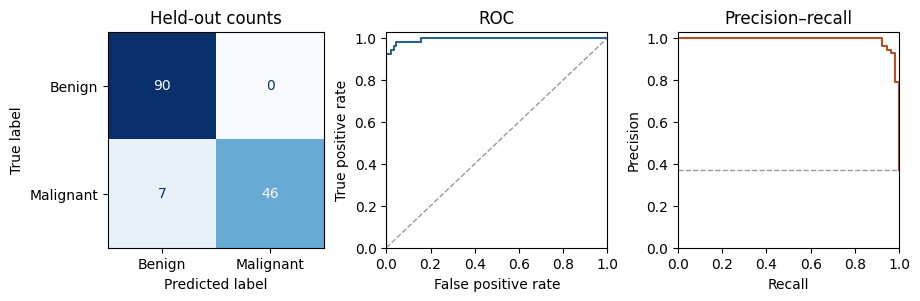

In [4]:
probability = classification_report(model, X, X_test, y, y_test)
plt.show()

## Reading the result

Highly overlapping classes can make repeated reweighting concentrate on a handful of difficult examples.

## References

[scikit-learn, AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html)

[Wolberg, Mangasarian, Street and Street, Breast Cancer Wisconsin (Diagnostic), UCI, CC BY 4.0](https://doi.org/10.24432/C5DW2B)